# Analysis Dependency antar label

Jadi intinya mau tau apakah kemunculan satu label berkaitan dengan kemunculan label lainnya

Read & Hollmén, “Multi-label Classification using Labels as Hidden Nodes”

https://arxiv.org/html/1503.09022v3

Di bagian Introduction, paper menjelaskan bahwa pada multilabel classification, satu instance dapat memiliki beberapa label, dan salah satu pendekatan yang digunakan adalah Binary Relevance (BR).

Pada BR, setiap label dianggap secara independen.

Masalahnya, kalau label-label tersebut sebenarnya mempunyai hubungan, memperlakukan semuanya sebagai benar-benar independen bisa kehilangan informasi hubungan antar-label.

Paper tersebut kemudian membahas pendekatan Classifier Chains (CC), di mana prediksi label sebelumnya dapat digunakan sebagai informasi untuk memprediksi label berikutnya.

Jadi informasi dari label sebelumnya dapat digunakan ketika melakukan prediksi label berikutnya.

menemukan bahwa dua label sering muncul bersama ≠ otomatis berarti model harus menggabungkan atau menghubungkan kedua label tersebut.

## Ada dua jenis "ketergantungan" yang perlu dibedakan

Paper Dembczyński et al., “On label dependence and loss minimization in multi-label classification” sangat membantu untuk menjelaskan hal ini.

A. Marginal dependence
“Apakah dua label cenderung muncul bersama?” -> pake statistik 

B. Conditional dependence
Pertanyaannya bukan sekadar:

“Apakah A dan B berhubungan?”

tetapi:

“Apakah A masih memberikan informasi tentang B setelah mempertimbangkan informasi lainnya?”

Nah, ini sudah masuk ke level yang lebih dalam dan biasanya berhubungan dengan bagaimana dependency dimodelkan dalam algoritma multilabel.

## Sumber paper yang menjadi dasar
* Read & Hollmén (2015), Multi-label Classification using Labels as Hidden Nodes — terutama bagian Introduction dan pembahasan Binary Relevance / Classifier Chains serta label dependence. Paper ini penting untuk menjelaskan bahwa multilabel classification dapat memiliki hubungan antar-label, tetapi korelasi yang diamati belum otomatis berarti dependency yang harus dimodelkan.
* Dembczyński et al. (2012), On label dependence and loss minimization in multi-label classification — terutama pembahasan mengenai label dependence, termasuk pembedaan marginal dependence dan conditional dependence.
* Tenenboim-Chekina, Rokach & Shapira (2010), Identification of label dependencies for multi-label classification — relevan sebagai dasar penggunaan Chi-square test of independence untuk mengidentifikasi hubungan antar-label.
* Cheng et al., On Label Dependence in Multi-Label Classification — relevan untuk pembahasan lebih lanjut mengenai bagaimana dependency antar-label dipandang dalam multilabel classification.

Co-occurrence → hubungan secara frekuensi
Chi-square → uji signifikansi ketergantungan
Mutual Information → mengukur tingkat informasi yang dibagi
Pearson → ukuran arah/kekuatan hubungan

In [2]:
import numpy as np  
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Majority Voting
df = pd.read_csv("./dataset/data_thesis_final.csv")
df

,Unnamed: 0,text_id,annotators_id,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,sexually_explicit,cleaned_text,processed_text
0,0,2026-01-01 00:00:00,"['7', '15']",Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,0,Wajah jurnalis dibalut perban saat melaporkan ...,wajah jurnalis dibalut perban saat melaporkan ...
1,1,2026-01-10 00:00:00,"['7', '15']",Elektabilitas Paslon 02 sebentar lagi terjun b...,Disabilitas,0,0,1,0,0,0,0,0,Elektabilitas pasangan calon 02 sebentar lagi ...,elektabilitas pasangan calon sebentar lagi ter...
2,2,1-1001,"['10', '18']","Kristen, Hindu, Islam dapat perlakuan istimewa...",Kristen,0,0,1,0,0,0,0,0,"Kristen, Hindu, Islam dapat perlakuan istimewa...","kristen, hindu, islam dapat perlakuan istimewa..."
3,3,1-1004,"['10', '18']","Masyarakat Kristen, Hindu, Budha, dan etnis Ti...","Kristen, Tionghoa",0,0,0,0,0,0,0,0,"Masyarakat Kristen, Hindu, Buddha, dan etnis T...","masyarakat kristen, hindu, buddha, dan etnis t..."
4,4,1-1005,"['10', '18']",Cina Mengirimkan Satelit Penginderaan Jauh Bar...,Tionghoa,0,0,0,0,0,0,0,0,Cina mengirimkan satelit penginderaan jauh bar...,cina mengirimkan satelit penginderaan jauh bar...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26374,26374,4-994,['19'],@pippsstudy abis packing nnt ingfokan cowo kri...,Kristen,0,0,0,0,0,0,0,0,"@pippsstudy Abis packing, nanti infokan cowok ...","abis packing, nanti infokan cowok kristen."
26375,26375,4-995,['19'],Akun WhatsApp Pj Bupati Tegal Agustyarsah,UNKNOWN,0,0,0,0,0,0,0,0,Akun WhatsApp Pj Bupati Tegal Agustyarsah,akun whatsapp pj bupati tegal agustyarsah
26376,26376,4-996,['19'],Buldoser Israel Menabrak Pengungsi Pasien Ruma...,"Jewish, Rohingya",0,0,1,0,0,0,0,0,Bulldozer Israel menabrak pengungsi pasien Rum...,bulldozer israel menabrak pengungsi pasien rum...
26377,26377,4-998,['19'],Perayaan Chinese New Year tahun ini ya akan ma...,Tionghoa,0,0,0,0,0,0,0,0,Perayaan Chinese New Year tahun ini akan makin...,perayaan chinese new year tahun ini akan makin...


In [42]:
LABEL_COLS = [
    "insults",
    "identity_attack",
    "polarized",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit"
]

In [25]:
corr_toxicity = (
    df[LABEL_COLS + ["toxicity"]]
    .corr(method="pearson")["toxicity"]
    .drop("toxicity")
    .sort_values(ascending=False)
)

corr_toxicity

insults                          0.642142
identity_attack                  0.618421
profanity_obscenity              0.370144
polarized                        0.260466
threat_incitement_to_violence    0.201599
sexually_explicit                0.150734
Name: toxicity, dtype: float64

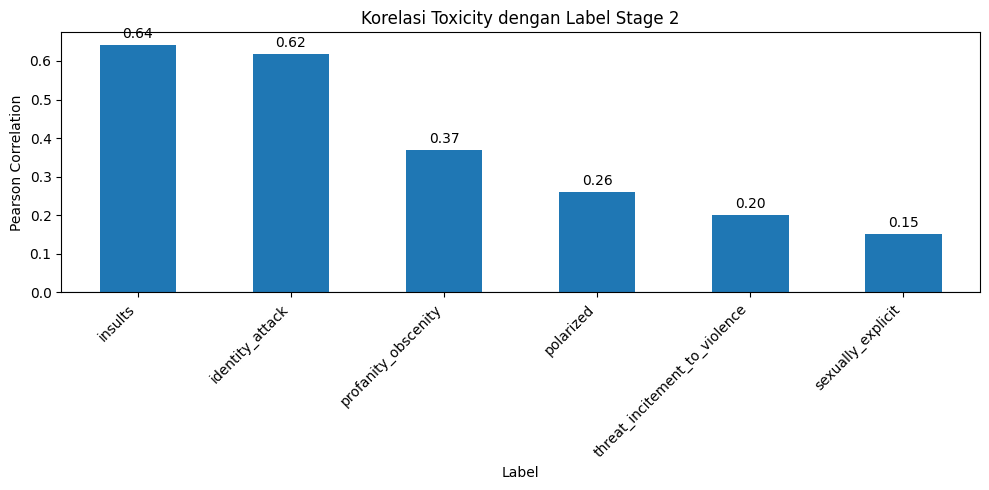

In [27]:
ax = corr_toxicity.plot(kind='bar', figsize=(10, 5))

plt.title('Korelasi Toxicity dengan Label Stage 2')
plt.xlabel('Label')
plt.ylabel('Pearson Correlation')
plt.xticks(rotation=45, ha='right')
plt.axhline(0, linewidth=0.8)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

In [43]:
co_occurrence_toxicity = df[LABEL_COLS + ["toxicity"]].T.dot(df[LABEL_COLS])

co_occurrence_toxicity

,insults,identity_attack,polarized,threat_incitement_to_violence,profanity_obscenity,sexually_explicit
insults,1064,288,602,8,162,4
identity_attack,288,1014,655,25,104,10
polarized,602,655,4828,78,136,2
threat_incitement_to_violence,8,25,78,109,5,0
profanity_obscenity,162,104,136,5,361,17
sexually_explicit,4,10,2,0,17,62
toxicity,1055,994,1203,108,359,61


# FULL DATASET

In [44]:
corr = df[LABEL_COLS].corr(method="pearson")

corr

,insults,identity_attack,polarized,threat_incitement_to_violence,profanity_obscenity,sexually_explicit
insults,1.000000,0.247648,0.202934,0.010824,0.244523,0.005966
identity_attack,0.247648,1.000000,0.239365,0.063966,0.152957,0.031015
polarized,0.202934,0.239365,1.000000,0.088716,0.059007,-0.018924
threat_incitement_to_violence,0.010824,0.063966,0.088716,1.000000,0.017845,-0.003127
profanity_obscenity,0.244523,0.152957,0.059007,0.017845,1.000000,0.108835
sexually_explicit,0.005966,0.031015,-0.018924,-0.003127,0.108835,1.000000


<Axes: >

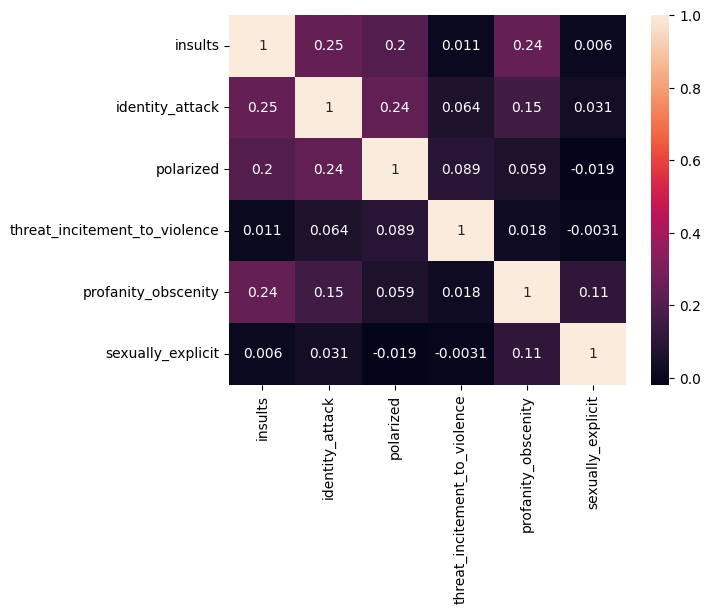

In [5]:
import seaborn as sns

sns.heatmap(corr, annot=True)

In [ ]:
# Co-occurrence
# -> secara sederhana berarti seberapa sering dua hal muncul secara bersamaan dalam data.

import numpy as np

co_occurrence = df[LABEL_COLS].T.dot(df[LABEL_COLS])

co_occurrence

,insults,identity_attack,polarized,threat_incitement_to_violence,profanity_obscenity,sexually_explicit
insults,1064,288,602,8,162,4
identity_attack,288,1014,655,25,104,10
polarized,602,655,4828,78,136,2
threat_incitement_to_violence,8,25,78,109,5,0
profanity_obscenity,162,104,136,5,361,17
sexually_explicit,4,10,2,0,17,62


In [7]:
label_counts = df[LABEL_COLS].sum().sort_values(ascending=False)

print(label_counts)

polarized                        4828
insults                          1064
identity_attack                  1014
profanity_obscenity               361
threat_incitement_to_violence     109
sexually_explicit                  62
dtype: int64


In [ ]:
# Jaccard Similarity
# -> Dari semua data yang memiliki minimal salah satu dari dua label, seberapa banyak yang memiliki keduanya?
# insults dan profanity_obscenity memiliki Jaccard similarity sebesar 0.57, yang menunjukkan bahwa kedua label tersebut cukup sering muncul pada data yang sama dibandingkan dengan pasangan label lainnya.

from sklearn.metrics import jaccard_score

jaccard_matrix = pd.DataFrame(
    index=LABEL_COLS,
    columns=LABEL_COLS,
    dtype=float
)

for label1 in LABEL_COLS:
    for label2 in LABEL_COLS:
        jaccard_matrix.loc[label1, label2] = jaccard_score(
            df[label1],
            df[label2]
        )

jaccard_matrix

,insults,identity_attack,polarized,threat_incitement_to_violence,profanity_obscenity,sexually_explicit
insults,1.000000,0.160894,0.113800,0.006867,0.128266,0.003565
identity_attack,0.160894,1.000000,0.126277,0.022769,0.081825,0.009381
polarized,0.113800,0.126277,1.000000,0.016053,0.026915,0.000409
threat_incitement_to_violence,0.006867,0.022769,0.016053,1.000000,0.010753,0.000000
profanity_obscenity,0.128266,0.081825,0.026915,0.010753,1.000000,0.041872
sexually_explicit,0.003565,0.009381,0.000409,0.000000,0.041872,1.000000


<Axes: >

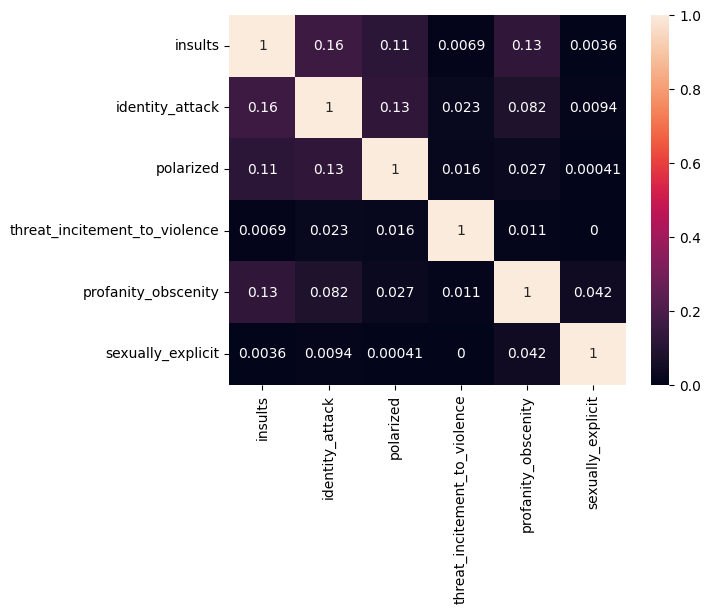

In [28]:
sns.heatmap(jaccard_matrix, annot=True)

In [9]:
print("====== CORRELATION =======")
print(corr)
print()

print("====== CO Occurance ======")
print(co_occurrence)
print()

print("====== JACCARD MATRIX =====")
print(jaccard_matrix)
print()

====== CORRELATION =======
                                insults  identity_attack  polarized  \
insults                        1.000000         0.247648   0.202934   
identity_attack                0.247648         1.000000   0.239365   
polarized                      0.202934         0.239365   1.000000   
threat_incitement_to_violence  0.010824         0.063966   0.088716   
profanity_obscenity            0.244523         0.152957   0.059007   
sexually_explicit              0.005966         0.031015  -0.018924   

                               threat_incitement_to_violence  \
insults                                             0.010824   
identity_attack                                     0.063966   
polarized                                           0.088716   
threat_incitement_to_violence                       1.000000   
profanity_obscenity                                 0.017845   
sexually_explicit                                  -0.003127   

                          

In [33]:
from scipy.stats import chi2_contingency
from sklearn.metrics import mutual_info_score

In [35]:
results = []

for i in range(len(LABEL_COLS)):
    for j in range(i + 1, len(LABEL_COLS)):

        label_1 = LABEL_COLS[i]
        label_2 = LABEL_COLS[j]

        # Contingency table
        table = pd.crosstab(
            df[label_1],
            df[label_2]
        )

        # Chi-square
        chi2, p_value, dof, expected = chi2_contingency(table)

        results.append({
            "Label 1": label_1,
            "Label 2": label_2,
            "Chi-Square": chi2,
            "p-value": p_value
        })


df_dependency = pd.DataFrame(results)

df_dependency

,Label 1,Label 2,Chi-Square,p-value
0,insults,identity_attack,1611.274106,0.000000e+00
1,insults,polarized,1083.681405,1.163221e-237
2,insults,threat_incitement_to_violence,2.292264,1.300201e-01
3,insults,profanity_obscenity,1566.565692,0.000000e+00
4,insults,sexually_explicit,0.417015,5.184301e-01
5,identity_attack,polarized,1508.177803,0.000000e+00
6,identity_attack,threat_incitement_to_violence,102.810790,3.687357e-24
7,identity_attack,profanity_obscenity,610.327189,9.496964e-135
8,identity_attack,sexually_explicit,22.153195,2.517367e-06
9,polarized,threat_incitement_to_violence,204.056089,2.721108e-46


In [41]:
df_dependency["Significant"] = np.where(
    df_dependency["p-value"] < 0.05,
    "Dependent",
    "Independent"
)

df_dependency

,Label 1,Label 2,Chi-Square,p-value,Significant
0,insults,identity_attack,1611.274106,0.000000e+00,Dependent
1,insults,polarized,1083.681405,1.163221e-237,Dependent
2,insults,threat_incitement_to_violence,2.292264,1.300201e-01,Independent
3,insults,profanity_obscenity,1566.565692,0.000000e+00,Dependent
4,insults,sexually_explicit,0.417015,5.184301e-01,Independent
5,identity_attack,polarized,1508.177803,0.000000e+00,Dependent
6,identity_attack,threat_incitement_to_violence,102.810790,3.687357e-24,Dependent
7,identity_attack,profanity_obscenity,610.327189,9.496964e-135,Dependent
8,identity_attack,sexually_explicit,22.153195,2.517367e-06,Dependent
9,polarized,threat_incitement_to_violence,204.056089,2.721108e-46,Dependent


In [ ]:
results_MI = []

for i in range(len(LABEL_COLS)):
    for j in range(i + 1, len(LABEL_COLS)):

        label_1 = LABEL_COLS[i]
        label_2 = LABEL_COLS[j]

        # Contingency table
        table = pd.crosstab(
            df[label_1],
            df[label_2]
        )

        # Mutual Information
        mi = mutual_info_score(
            df[label_1],
            df[label_2]
        )

        results_MI.append({
            "Label 1": label_1,
            "Label 2": label_2,
            "Mutual Information": mi
        })

df_dependency_MI = pd.DataFrame(results_MI)

df_dependency_MI

,Label 1,Label 2,Mutual Information
0,insults,identity_attack,0.014530
1,insults,polarized,0.015536
2,insults,threat_incitement_to_violence,0.000048
3,insults,profanity_obscenity,0.011042
4,insults,sexually_explicit,0.000015
5,identity_attack,polarized,0.021066
6,identity_attack,threat_incitement_to_violence,0.000997
7,identity_attack,profanity_obscenity,0.005177
8,identity_attack,sexually_explicit,0.000275
9,polarized,threat_incitement_to_violence,0.002808


In [45]:
results = []

for i in range(len(LABEL_COLS)):
    for j in range(i + 1, len(LABEL_COLS)):

        label_1 = LABEL_COLS[i]
        label_2 = LABEL_COLS[j]

        x = df[label_1]
        y = df[label_2]

        # =========================================================
        # 1. CO-OCCURRENCE
        # =========================================================
        cooccurrence = ((x == 1) & (y == 1)).sum()

        # =========================================================
        # 2. CHI-SQUARE
        # =========================================================
        table = pd.crosstab(x, y)

        chi2, p_value, dof, expected = chi2_contingency(table)

        # =========================================================
        # 3. MUTUAL INFORMATION
        # =========================================================
        mi = mutual_info_score(x, y)

        # =========================================================
        # 4. PEARSON CORRELATION
        # =========================================================
        pearson = x.corr(y, method="pearson")

        # =========================================================
        # SIMPAN HASIL
        # =========================================================
        results.append({
            "Label 1": label_1,
            "Label 2": label_2,

            "Co-occurrence": cooccurrence,

            "Chi-Square": chi2,
            "p-value": p_value,

            "Mutual Information": mi,

            "Pearson": pearson
        })


df_dependency = pd.DataFrame(results)

df_dependency

,Label 1,Label 2,Co-occurrence,Chi-Square,p-value,Mutual Information,Pearson
0,insults,identity_attack,288,1611.274106,0.000000e+00,0.014530,0.247648
1,insults,polarized,602,1083.681405,1.163221e-237,0.015536,0.202934
2,insults,threat_incitement_to_violence,8,2.292264,1.300201e-01,0.000048,0.010824
3,insults,profanity_obscenity,162,1566.565692,0.000000e+00,0.011042,0.244523
4,insults,sexually_explicit,4,0.417015,5.184301e-01,0.000015,0.005966
5,identity_attack,polarized,655,1508.177803,0.000000e+00,0.021066,0.239365
6,identity_attack,threat_incitement_to_violence,25,102.810790,3.687357e-24,0.000997,0.063966
7,identity_attack,profanity_obscenity,104,610.327189,9.496964e-135,0.005177,0.152957
8,identity_attack,sexually_explicit,10,22.153195,2.517367e-06,0.000275,0.031015
9,polarized,threat_incitement_to_violence,78,204.056089,2.721108e-46,0.002808,0.088716


In [46]:
df_dependency["Significant"] = np.where(
    df_dependency["p-value"] < 0.05,
    "Dependent",
    "Independent"
)

df_dependency

,Label 1,Label 2,Co-occurrence,Chi-Square,p-value,Mutual Information,Pearson,Significant
0,insults,identity_attack,288,1611.274106,0.000000e+00,0.014530,0.247648,Dependent
1,insults,polarized,602,1083.681405,1.163221e-237,0.015536,0.202934,Dependent
2,insults,threat_incitement_to_violence,8,2.292264,1.300201e-01,0.000048,0.010824,Independent
3,insults,profanity_obscenity,162,1566.565692,0.000000e+00,0.011042,0.244523,Dependent
4,insults,sexually_explicit,4,0.417015,5.184301e-01,0.000015,0.005966,Independent
5,identity_attack,polarized,655,1508.177803,0.000000e+00,0.021066,0.239365,Dependent
6,identity_attack,threat_incitement_to_violence,25,102.810790,3.687357e-24,0.000997,0.063966,Dependent
7,identity_attack,profanity_obscenity,104,610.327189,9.496964e-135,0.005177,0.152957,Dependent
8,identity_attack,sexually_explicit,10,22.153195,2.517367e-06,0.000275,0.031015,Dependent
9,polarized,threat_incitement_to_violence,78,204.056089,2.721108e-46,0.002808,0.088716,Dependent


In [51]:
# =========================================================
# 1. CO-OCCURRENCE
# =========================================================
df_cooccurrence = (
    df_dependency
    .sort_values(
        by="Co-occurrence",
        ascending=False
    )
    .reset_index(drop=True)
)
df_cooccurrence

,Label 1,Label 2,Co-occurrence,Chi-Square,p-value,Mutual Information,Pearson,Significant
0,identity_attack,polarized,655,1508.177803,0.000000e+00,0.021066,0.239365,Dependent
1,insults,polarized,602,1083.681405,1.163221e-237,0.015536,0.202934,Dependent
2,insults,identity_attack,288,1611.274106,0.000000e+00,0.014530,0.247648,Dependent
3,insults,profanity_obscenity,162,1566.565692,0.000000e+00,0.011042,0.244523,Dependent
4,polarized,profanity_obscenity,136,90.538022,1.814562e-21,0.001437,0.059007,Dependent
5,identity_attack,profanity_obscenity,104,610.327189,9.496964e-135,0.005177,0.152957,Dependent
6,polarized,threat_incitement_to_violence,78,204.056089,2.721108e-46,0.002808,0.088716,Dependent
7,identity_attack,threat_incitement_to_violence,25,102.810790,3.687357e-24,0.000997,0.063966,Dependent
8,profanity_obscenity,sexually_explicit,17,293.412733,8.973614e-66,0.001423,0.108835,Dependent
9,identity_attack,sexually_explicit,10,22.153195,2.517367e-06,0.000275,0.031015,Dependent


In [52]:
# =========================================================
# 2. CHI-SQUARE
# =========================================================
df_chi_square = (
    df_dependency
    .sort_values(
        by="Chi-Square",
        ascending=False
    )
    .reset_index(drop=True)
)

df_chi_square

,Label 1,Label 2,Co-occurrence,Chi-Square,p-value,Mutual Information,Pearson,Significant
0,insults,identity_attack,288,1611.274106,0.000000e+00,0.014530,0.247648,Dependent
1,insults,profanity_obscenity,162,1566.565692,0.000000e+00,0.011042,0.244523,Dependent
2,identity_attack,polarized,655,1508.177803,0.000000e+00,0.021066,0.239365,Dependent
3,insults,polarized,602,1083.681405,1.163221e-237,0.015536,0.202934,Dependent
4,identity_attack,profanity_obscenity,104,610.327189,9.496964e-135,0.005177,0.152957,Dependent
5,profanity_obscenity,sexually_explicit,17,293.412733,8.973614e-66,0.001423,0.108835,Dependent
6,polarized,threat_incitement_to_violence,78,204.056089,2.721108e-46,0.002808,0.088716,Dependent
7,identity_attack,threat_incitement_to_violence,25,102.810790,3.687357e-24,0.000997,0.063966,Dependent
8,polarized,profanity_obscenity,136,90.538022,1.814562e-21,0.001437,0.059007,Dependent
9,identity_attack,sexually_explicit,10,22.153195,2.517367e-06,0.000275,0.031015,Dependent


In [53]:
# =========================================================
# 3. MUTUAL INFORMATION
# =========================================================
df_mutual_information = (
    df_dependency
    .sort_values(
        by="Mutual Information",
        ascending=False
    )
    .reset_index(drop=True)
)
df_mutual_information

,Label 1,Label 2,Co-occurrence,Chi-Square,p-value,Mutual Information,Pearson,Significant
0,identity_attack,polarized,655,1508.177803,0.000000e+00,0.021066,0.239365,Dependent
1,insults,polarized,602,1083.681405,1.163221e-237,0.015536,0.202934,Dependent
2,insults,identity_attack,288,1611.274106,0.000000e+00,0.014530,0.247648,Dependent
3,insults,profanity_obscenity,162,1566.565692,0.000000e+00,0.011042,0.244523,Dependent
4,identity_attack,profanity_obscenity,104,610.327189,9.496964e-135,0.005177,0.152957,Dependent
5,polarized,threat_incitement_to_violence,78,204.056089,2.721108e-46,0.002808,0.088716,Dependent
6,polarized,profanity_obscenity,136,90.538022,1.814562e-21,0.001437,0.059007,Dependent
7,profanity_obscenity,sexually_explicit,17,293.412733,8.973614e-66,0.001423,0.108835,Dependent
8,identity_attack,threat_incitement_to_violence,25,102.810790,3.687357e-24,0.000997,0.063966,Dependent
9,identity_attack,sexually_explicit,10,22.153195,2.517367e-06,0.000275,0.031015,Dependent


In [54]:
# =========================================================
# 4. PEARSON
# =========================================================
df_pearson = (
    df_dependency
    .sort_values(
        by="Pearson",
        ascending=False
    )
    .reset_index(drop=True)
)
df_pearson

,Label 1,Label 2,Co-occurrence,Chi-Square,p-value,Mutual Information,Pearson,Significant
0,insults,identity_attack,288,1611.274106,0.000000e+00,0.014530,0.247648,Dependent
1,insults,profanity_obscenity,162,1566.565692,0.000000e+00,0.011042,0.244523,Dependent
2,identity_attack,polarized,655,1508.177803,0.000000e+00,0.021066,0.239365,Dependent
3,insults,polarized,602,1083.681405,1.163221e-237,0.015536,0.202934,Dependent
4,identity_attack,profanity_obscenity,104,610.327189,9.496964e-135,0.005177,0.152957,Dependent
5,profanity_obscenity,sexually_explicit,17,293.412733,8.973614e-66,0.001423,0.108835,Dependent
6,polarized,threat_incitement_to_violence,78,204.056089,2.721108e-46,0.002808,0.088716,Dependent
7,identity_attack,threat_incitement_to_violence,25,102.810790,3.687357e-24,0.000997,0.063966,Dependent
8,polarized,profanity_obscenity,136,90.538022,1.814562e-21,0.001437,0.059007,Dependent
9,identity_attack,sexually_explicit,10,22.153195,2.517367e-06,0.000275,0.031015,Dependent


# TOXIC ONLY

In [12]:
df_2 = df[df['toxicity'] == 1]
df_2

,Unnamed: 0,text_id,annotators_id,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,sexually_explicit,cleaned_text,processed_text
14,14,1-1016,"['10', '18']",Video “Tentara Cina Komunis Tiongkok Masuk Ind...,Tionghoa,0,1,1,0,0,0,0,0,"Video ""Tentara Cina Komunis Tiongkok Masuk Ind...",video tentara cina komunis tiongkok masuk indo...
18,18,1-1021,"['10', '18']",GAMBAR GANJAR PRANOWO BERSALAMAN DENGAN PRESID...,UNKNOWN,0,1,1,0,0,0,0,0,Gambar Ganjar Pranowo bersalaman dengan Presid...,gambar ganjar pranowo bersalaman dengan presid...
23,23,1-1026,"['10', '18']",Tank dan Pasukan Bersenjata Dalam Video Ini Si...,UNKNOWN,0,1,1,0,0,1,0,0,Tank dan pasukan bersenjata dalam video ini: s...,tank dan pasukan bersenjata dalam video ini si...
28,28,1-1033,"['10', '18']","China Itu Pinter Menciptakan Yg Serba Palsu,Bi...",Tionghoa,0,1,0,0,0,1,0,0,"China itu pintar menciptakan yang serba palsu,...","china itu pintar menciptakan yang serba palsu,..."
32,32,1-1040,"['10', '18']",KADRUN KATANYA ANTI CHINA MAKAN DIKASIH SAMA O...,Tionghoa,0,1,0,0,0,0,1,0,"Kadrun katanya anti-China, makan dikasih sama ...","kadrun katanya antichina, makan dikasih sama o..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26316,26316,4-941,['19'],Hati2 bae samo orang ni #homo GAY # ke banci o...,LGBTQ+,0,1,0,0,0,1,0,0,Hati-hati sama orang ini #homo GAY #ke banci. ...,hatihati sama orang ini homo gay ke banci. ora...
26317,26317,4-942,['19'],@Heraloebss Usir Rohingya dari Aceh dan dari s...,Rohingya,0,1,1,0,1,0,1,0,@Heraloebss Usir Rohingya dari Aceh dan dari s...,usir rohingya dari aceh dan dari seluruh wilay...
26322,26322,4-947,['19'],Bismillah... Semoga orang yang mati-matian mem...,Syiah,0,1,1,0,0,0,1,0,Bismillah. Semoga orang yang mati-matian membe...,bismillah. semoga orang yang matimatian membel...
26338,26338,4-961,"['19', '18']","Gila ya , kalau umat bersatu habis juga itu ge...","LGBTQ+, Jewish, Disabilitas",0,1,1,0,0,1,0,0,"Gila ya, kalau umat bersatu, habis juga itu ge...","gila ya, kalau umat bersatu, habis juga itu ge..."


In [29]:
label_counts_2 = df_2[LABEL_COLS].sum().sort_values(ascending=False)

print(label_counts_2)

polarized                        1203
insults                          1055
identity_attack                   994
profanity_obscenity               359
threat_incitement_to_violence     108
sexually_explicit                  61
dtype: int64


In [13]:
corr_2 = df_2[LABEL_COLS].corr(method="pearson")

corr_2

,insults,identity_attack,polarized,threat_incitement_to_violence,profanity_obscenity,sexually_explicit
insults,1.000000,-0.254233,0.110788,-0.159963,0.009708,-0.121771
identity_attack,-0.254233,1.000000,0.237865,-0.080596,-0.108519,-0.082108
polarized,0.110788,0.237865,1.000000,0.091844,-0.102886,-0.151406
threat_incitement_to_violence,-0.159963,-0.080596,0.091844,1.000000,-0.062904,-0.035071
profanity_obscenity,0.009708,-0.108519,-0.102886,-0.062904,1.000000,0.058431
sexually_explicit,-0.121771,-0.082108,-0.151406,-0.035071,0.058431,1.000000


<Axes: >

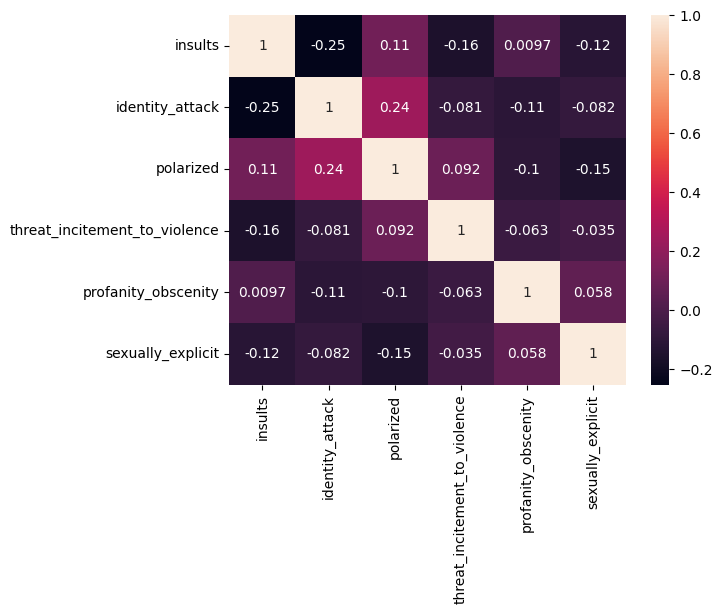

In [14]:
sns.heatmap(corr_2, annot=True)

In [ ]:
co_occurrence_2 = df_2[LABEL_COLS].T.dot(df_2[LABEL_COLS])

co_occurrence_2

,insults,identity_attack,polarized,threat_incitement_to_violence,profanity_obscenity,sexually_explicit
insults,1055,288,595,8,162,4
identity_attack,288,994,639,25,103,10
polarized,595,639,1203,77,136,2
threat_incitement_to_violence,8,25,77,108,5,0
profanity_obscenity,162,103,136,5,359,17
sexually_explicit,4,10,2,0,17,61


In [32]:
df_2.count()

Unnamed: 0                       2399
text_id                          2399
annotators_id                    2399
text                             2399
topic                            2399
is_noise_or_spam_text            2399
toxicity                         2399
polarized                        2399
profanity_obscenity              2399
threat_incitement_to_violence    2399
insults                          2399
identity_attack                  2399
sexually_explicit                2399
cleaned_text                     2399
processed_text                   2399
dtype: int64